In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

p = print
d = display

In [2]:
Carpeta_Proyecto = Path.cwd().parent
Carpeta_listos = Carpeta_Proyecto / "Dataset" / "M_Listos"
p(Carpeta_listos)

/home/Ian/prediccion_red/Dataset/M_Listos


### cargar los datos de MNIST

In [3]:
df_e = pd.read_csv(Carpeta_listos / "M_entre.csv")
df_p = pd.read_csv(Carpeta_listos / "M_prueb.csv")
p(df_e.shape, df_p.shape)
d(df_e.head())


(60000, 785) (10000, 785)


,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,respuesta
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9


In [4]:
df_e.info()

<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 785 entries, 0 to respuesta
dtypes: int64(785)
memory usage: 359.3 MB


### separar X e Y

In [5]:
Xtr = df_e.drop(columns="respuesta") / 255.0
Ytr = df_e["respuesta"]
Xts = df_p.drop(columns="respuesta") / 255.0
Yts = df_p["respuesta"]

p("Datos de entrenamiento:", len(Xtr))
p("Datos de prueba:", len(Xts))

Datos de entrenamiento: 60000
Datos de prueba: 10000


### muestra de 10 000

In [6]:
from sklearn.model_selection import train_test_split

Xmuestra, _, Ymuestra, _ = train_test_split(Xtr, Ytr, train_size=10000, random_state=42, stratify=Ytr)
p("Muestra:", len(Xmuestra))
p(Ymuestra.value_counts().sort_index())

Muestra: 10000
respuesta
0     987
1    1124
2     993
3    1022
4     974
5     904
6     986
7    1044
8     975
9     991
Name: count, dtype: int64


### regresión lineal

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score

model_lineal = LinearRegression()
model_lineal.fit(Xmuestra, Ymuestra)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](784,)","[ 0.,-0.,-0.,..., 0., 0., 0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](784,)","['0','1','2',...,'781','782','783']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.977
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,784
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(676)


### predicciones de la regresión lineal

In [8]:
pred_lineal_continua = model_lineal.predict(Xts)
p("Primeras predicciones:", pred_lineal_continua[:10].round(2))
p("Respuestas reales:    ", Yts[:10].values)

Primeras predicciones: [6.04 3.33 1.58 1.24 4.05 1.48 7.26 5.62 3.46 8.7 ]
Respuestas reales:     [7 2 1 0 4 1 4 9 5 9]


### exactitud de la regresión lineal

In [9]:
from sklearn.metrics import accuracy_score

pred_lineal = np.clip(np.round(pred_lineal_continua), 0, 9).astype(int)
accuracy_lineal = accuracy_score(Yts, pred_lineal)
p("Accuracy:", accuracy_lineal)

Accuracy: 0.226


### regresión logística

In [10]:
from sklearn.linear_model import LogisticRegression
import time

inicio = time.time()
model_logis = LogisticRegression(max_iter=1000)
model_logis.fit(Xtr, Ytr)
p("Tiempo:", round(time.time() - inicio, 1), "segundos")

Tiempo: 42.1 segundos


### exactitud de la regresión logística

In [11]:
pred_logis = model_logis.predict(Xts)
accuracy_logis = accuracy_score(Yts, pred_logis)

p("Primeras predicciones:", pred_logis[:10])
p("Respuestas reales:    ", Yts[:10].values)
p("Accuracy:", accuracy_logis)

Primeras predicciones: [7 2 1 0 4 1 4 9 6 9]
Respuestas reales:     [7 2 1 0 4 1 4 9 5 9]
Accuracy: 0.926


### árbol de decisión

In [12]:
from sklearn.tree import DecisionTreeClassifier

model_arbol = DecisionTreeClassifier(random_state=42)
model_arbol.fit(Xtr, Ytr)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

### exactitud del árbol de decisión

In [13]:
pred_arbol = model_arbol.predict(Xts)
accuracy_arbol = accuracy_score(Yts, pred_arbol)

p("Primeras predicciones:", pred_arbol[:10])
p("Respuestas reales:    ", Yts[:10].values)
p("Accuracy:", accuracy_arbol)

Primeras predicciones: [7 2 1 0 4 1 4 7 8 9]
Respuestas reales:     [7 2 1 0 4 1 4 9 5 9]
Accuracy: 0.8754


### KNN

In [14]:
from sklearn.neighbors import KNeighborsClassifier

model_knn = KNeighborsClassifier(n_neighbors=3, n_jobs=4)
model_knn.fit(Xtr, Ytr)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",4
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](10,)","[0,1,2,...,7,8,9]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### exactitud y tiempo del KNN

In [15]:
inicio = time.time()
pred_knn = model_knn.predict(Xts)
accuracy_knn = accuracy_score(Yts, pred_knn)

p("Primeras predicciones:", pred_knn[:10])
p("Respuestas reales:    ", Yts[:10].values)
p("Accuracy:", accuracy_knn)
p("Tiempo:", round(time.time() - inicio, 1), "segundos")

Primeras predicciones: [7 2 1 0 4 1 4 9 5 9]
Respuestas reales:     [7 2 1 0 4 1 4 9 5 9]
Accuracy: 0.9705
Tiempo: 4.0 segundos


### SVM

In [16]:
from sklearn.svm import SVC

X20, _, Y20, _ = train_test_split(Xtr, Ytr, train_size=20000, random_state=42, stratify=Ytr)

inicio = time.time()
model_svm = SVC(kernel="rbf", C=10, gamma="scale")
model_svm.fit(X20, Y20)
p("Tiempo:", round(time.time() - inicio, 1), "segundos")

Tiempo: 21.4 segundos


### exactitud del SVM

In [17]:
pred_svm = model_svm.predict(Xts)
accuracy_svm = accuracy_score(Yts, pred_svm)

p("Primeras predicciones:", pred_svm[:10])
p("Respuestas reales:    ", Yts[:10].values)
p("Accuracy:", accuracy_svm)

Primeras predicciones: [7 2 1 0 4 1 4 9 6 9]
Respuestas reales:     [7 2 1 0 4 1 4 9 5 9]
Accuracy: 0.9767


### comparar todos los modelos clásicos

In [18]:
resultados = pd.DataFrame({
    "Modelo": ["Regresión lineal", "Regresión logística", "Árbol de decisión", "KNN", "SVM"],
    "Accuracy": [accuracy_lineal, accuracy_logis, accuracy_arbol, accuracy_knn, accuracy_svm],
})
resultados["Porcentaje"] = (resultados["Accuracy"] * 100).round(2)
d(resultados.sort_values("Accuracy", ascending=False))

,Modelo,Accuracy,Porcentaje
4,SVM,0.9767,97.67
3,KNN,0.9705,97.05
1,Regresión logística,0.9260,92.60
2,Árbol de decisión,0.8754,87.54
0,Regresión lineal,0.2260,22.60


### precisión de cada modelo

In [19]:
from sklearn.metrics import precision_score

resultados["Precisión"] = [
    precision_score(Yts, pred_lineal, average="macro", zero_division=0),
    precision_score(Yts, pred_logis, average="macro"),
    precision_score(Yts, pred_arbol, average="macro"),
    precision_score(Yts, pred_knn, average="macro"),
    precision_score(Yts, pred_svm, average="macro"),
]
d(resultados.round(4).sort_values("Accuracy", ascending=False))

,Modelo,Accuracy,Porcentaje,Precisión
4,SVM,0.9767,97.67,0.9768
3,KNN,0.9705,97.05,0.9709
1,Regresión logística,0.9260,92.60,0.9250
2,Árbol de decisión,0.8754,87.54,0.8740
0,Regresión lineal,0.2260,22.60,0.2808


### matriz de confusión del SVM

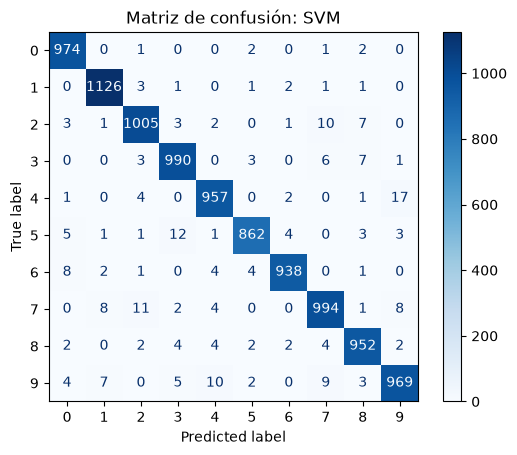

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(Yts, pred_svm, cmap="Blues")
plt.title("Matriz de confusión: SVM")
plt.show()

### validación cruzada

In [21]:
from sklearn.model_selection import cross_val_score

for k in [1, 3, 5, 7]:
    puntajes = cross_val_score(KNeighborsClassifier(n_neighbors=k, n_jobs=4), Xmuestra, Ymuestra, cv=5)
    p("K =", k, "| 5 pruebas:", puntajes.round(4), "| promedio:", round(puntajes.mean(), 4))

K = 1 | 5 pruebas: [0.944  0.947  0.954  0.9485 0.9495] | promedio: 0.9486
K = 3 | 5 pruebas: [0.9435 0.9375 0.945  0.9485 0.9475] | promedio: 0.9444
K = 5 | 5 pruebas: [0.9395 0.9405 0.9415 0.9455 0.946 ] | promedio: 0.9426
K = 7 | 5 pruebas: [0.935  0.938  0.9435 0.943  0.943 ] | promedio: 0.9405


### agrupar los dígitos con K-Means sin usar las respuestas

In [22]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=10, random_state=42, n_init=10)
grupos = km.fit_predict(Xmuestra)

tabla = pd.crosstab(pd.Series(grupos, name="Grupo"), pd.Series(Ymuestra.values, name="Dígito real"))
d(tabla)

Dígito real,0,1,2,3,4,5,6,7,8,9
Grupo,,,,,,,,,,
0,773,0,6,4,0,16,6,1,4,5
1,1,624,44,66,14,25,54,40,43,26
2,86,3,27,191,1,306,26,2,514,4
3,43,1,32,10,18,28,822,2,12,0
4,3,1,737,35,4,7,21,5,8,0
5,53,0,57,649,0,283,5,0,223,19
6,2,2,16,2,230,22,0,428,45,230
7,3,2,5,24,309,40,0,399,26,407
8,9,491,51,23,35,136,29,38,58,14


### porcentaje de imágenes que K-Means agrupó bien

In [23]:
asociacion = tabla.idxmax(axis=1)
prediccion_aproximada = pd.Series(grupos).map(asociacion)
coincide = prediccion_aproximada.values == Ymuestra.values

p("Cada grupo se parece más a este número:")
p(asociacion)
p("Coincidencias:", round(coincide.mean() * 100, 2), "%")

Cada grupo se parece más a este número:
Grupo
0    0
1    1
2    8
3    6
4    2
5    3
6    7
7    9
8    1
9    4
dtype: int64
Coincidencias: 58.08 %



## conclusión

Se probaron con los mismos datos de MNIST cinco modelos de aprendizaje supervisado vistos en clase y un modelo no supervisado.

| Modelo | Exactitud | Precisión |
|---|---|---|
| SVM | 97,67 % | 97,68 % |
| KNN | 97,05 % | 97,09 % |
| Regresión logística | 92,60 % | 92,50 % |
| Árbol de decisión | 87,54 % | 87,40 % |
| Regresión lineal | 22,60 % | 28,08 % |

- **Regresión lineal:** no sirve para reconocer números. Predice cantidades con decimales y trata los números como si estuvieran en fila, pero un 7 escrito a mano no se parece a un "6 y medio".
- **Regresión logística:** sí sirve, porque calcula la probabilidad de cada número y escoge el más probable, pero se queda en 92,60 %.
- **Árbol de decisión:** hace preguntas sobre píxeles fijos, y si el número está corrido o torcido, se equivoca más.
- **KNN:** acierta 97,05 % comparando cada imagen con las más parecidas. Con validación cruzada se comprobó que el mejor valor es K = 1, con un promedio de 94,86 % en 5 pruebas.
- **SVM:** es el mejor modelo clásico, con 97,67 %, pero es lento para aprender y por eso se entrenó solo con 20 000 imágenes.
- **K-Means:** agrupa por parecido sin conocer las respuestas, y coincide solo en un 58 % aproximadamente, porque mezcla números parecidos como el 3, el 5 y el 8. No sirve para reconocer números, pero sí para separar la tinta del papel, como se hizo en el cuaderno 02.

Los modelos clásicos miran cada imagen como 784 números sueltos. Por eso, para el proyecto se elige una **red neuronal convolucional**, que mira las formas de la imagen y además puede aprender números, letras y animales a la vez. Su entrenamiento y su comparación final con estos modelos están en el cuaderno 04.